# Prednost domačega terena in boj za vrh v Premier League (1992–2026)

Analiziram lestvice angleške Premier League od sezone 1992/93 do 2025/26 (34 sezon).
Podatke sem s strani [11v11.com](https://www.11v11.com/league-tables/) prenesel s
`prenos_strani.py` in jih z `izlusci_podatke.py` zapisal v `podatki/lestvice.csv`.

Za vsako sezono imam tri lestvice: **skupno**, **samo tekme doma** in **samo tekme v gosteh**,
za sezono 2019/20 pa še lestvici doma in v gosteh na dan 13. 3. 2020, ko so ligo prekinili
zaradi covida-19.

Glavni vprašanji analize:
1. **Ali domači teren vpliva na uspeh?** Kako pogosto zmagajo domači, ali dajo več golov in
   kaj se je zgodilo, ko so tekme igrali brez gledalcev?
2. **Kdo je na vrhu in kdo na dnu lestvice?** Kateri klubi so najpogosteje med prvimi tremi
   in med zadnjimi tremi ter kako velika je razlika med njimi?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

lestvice = pd.read_csv("podatki/lestvice.csv")

MODRA = "#2a78d6"
SIVA = "#b4b2aa"
ORANZNA = "#eb6834"
TEMNO_SIVA = "#3a3936"

print("Število vrstic po vrstah lestvic:")
print(lestvice["vrsta"].value_counts())
print("Število sezon:", lestvice["sezona"].nunique())
lestvice.head()

Število vrstic po vrstah lestvic:
vrsta
skupaj                    686
doma                      686
v_gosteh                  686
doma_do_prekinitve         20
v_gosteh_do_prekinitve     20
Name: count, dtype: int64
Število sezon: 34


,sezona,vrsta,mesto,klub,tekme,zmage,remiji,porazi,dani_goli,prejeti_goli,tocke
0,1992-93,skupaj,1,Manchester United,42,24,12,6,67,31,84
1,1992-93,skupaj,2,Aston Villa,42,21,11,10,57,40,74
2,1992-93,skupaj,3,Norwich City,42,21,9,12,61,65,72
3,1992-93,skupaj,4,Blackburn Rovers,42,20,11,11,68,46,71
4,1992-93,skupaj,5,Queens Park Rangers,42,17,12,13,63,55,63


Stolpci tabele: `sezona`, `vrsta` (skupaj, doma, v_gosteh, doma_do_prekinitve,
v_gosteh_do_prekinitve), `mesto`, `klub`, `tekme`, `zmage`, `remiji`, `porazi`,
`dani_goli`, `prejeti_goli` in `tocke`.

---
## 1. Ali domači teren vpliva na uspeh?

### 1.1 Zmage domačih, remiji in zmage gostov

Lestvica tekem doma vsebuje izide vseh tekem: zmaga na lestvici doma je zmaga domačih,
remi je remi, poraz na lestvici doma pa je zmaga gostov.

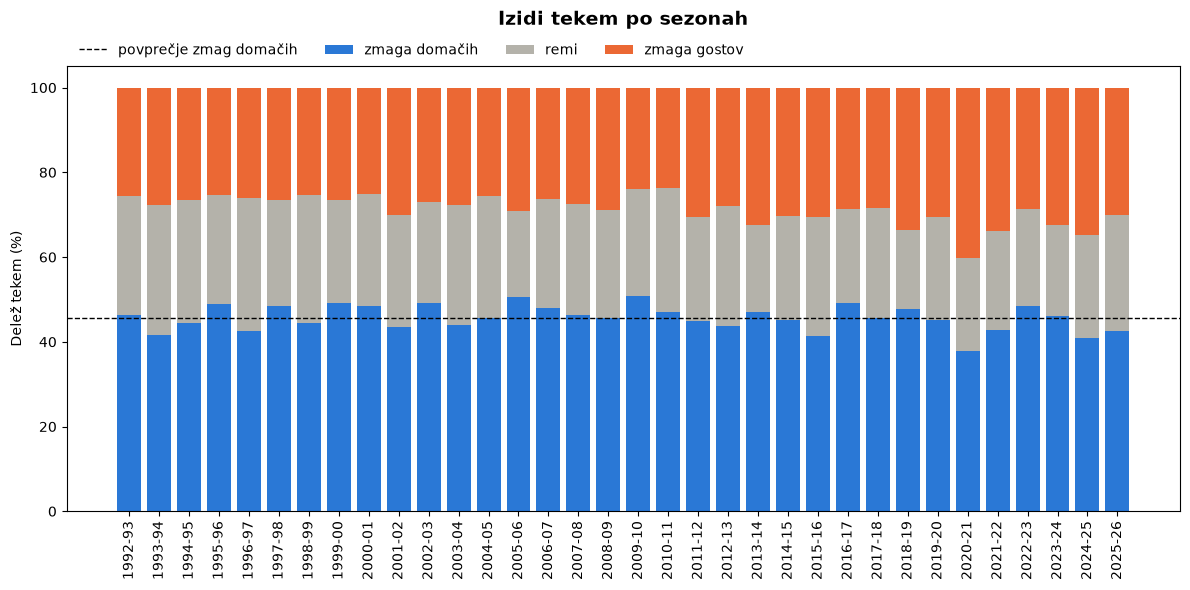

Zmage domačih: 45.7 %
Remiji:        25.6 %
Zmage gostov:  28.7 %
Sezone, v katerih gostje zmagali pogosteje kot domači: ['2020-21']


In [2]:
doma = lestvice[lestvice["vrsta"] == "doma"]
po_sezonah = doma.groupby("sezona")[["tekme", "zmage", "remiji", "porazi", "dani_goli", "prejeti_goli"]].sum()

zmage_domacih = po_sezonah["zmage"] / po_sezonah["tekme"] * 100
remiji = po_sezonah["remiji"] / po_sezonah["tekme"] * 100
zmage_gostov = po_sezonah["porazi"] / po_sezonah["tekme"] * 100

plt.figure(figsize=(12, 6))
x = range(len(po_sezonah))
plt.bar(x, zmage_domacih, color=MODRA, label="zmaga domačih")
plt.bar(x, remiji, bottom=zmage_domacih, color=SIVA, label="remi")
plt.bar(x, zmage_gostov, bottom=zmage_domacih + remiji, color=ORANZNA, label="zmaga gostov")
plt.axhline(zmage_domacih.mean(), color="black", linestyle="--", linewidth=1, label="povprečje zmag domačih")

plt.title("Izidi tekem po sezonah", fontsize=14, fontweight="bold", pad=30)
plt.ylabel("Delež tekem (%)")
plt.xticks(x, po_sezonah.index, rotation=90)
plt.legend(loc="upper left", bbox_to_anchor=(0, 1.08), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

vse = po_sezonah.sum()
print(f"Zmage domačih: {vse['zmage'] / vse['tekme'] * 100:.1f} %")
print(f"Remiji:        {vse['remiji'] / vse['tekme'] * 100:.1f} %")
print(f"Zmage gostov:  {vse['porazi'] / vse['tekme'] * 100:.1f} %")
print("Sezone, v katerih gostje zmagali pogosteje kot domači:",
      list(po_sezonah.index[zmage_gostov > zmage_domacih]))

### Ključne ugotovitve
> V vseh 34 sezonah so domači zmagali na 45,7 % tekem, gostje le na 28,7 %, preostalih 25,6 %
> tekem se je končalo z remijem. Domači so zmagali pogosteje kot gostje v vseh sezonah razen
> 2020/21, ko so tekme igrali brez gledalcev (domači 37,9 %, gostje 40,3 %).

### 1.2 Goli doma in v gosteh

Na lestvici doma so `dani_goli` goli domačih, `prejeti_goli` pa goli gostov.

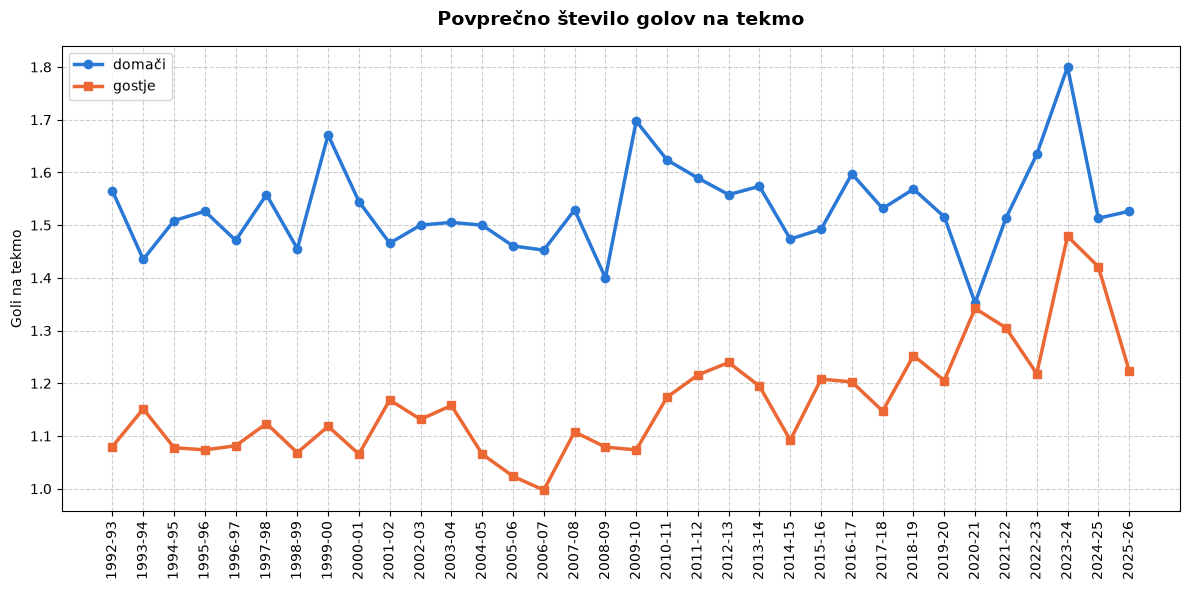

Domači: 1.53 gola na tekmo
Gostje: 1.16 gola na tekmo


In [3]:
goli_domacih = po_sezonah["dani_goli"] / po_sezonah["tekme"]
goli_gostov = po_sezonah["prejeti_goli"] / po_sezonah["tekme"]

plt.figure(figsize=(12, 6))
plt.plot(po_sezonah.index, goli_domacih, marker="o", color=MODRA, linewidth=2.5, label="domači")
plt.plot(po_sezonah.index, goli_gostov, marker="s", color=ORANZNA, linewidth=2.5, label="gostje")

plt.title("Povprečno število golov na tekmo", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Goli na tekmo")
plt.xticks(rotation=90)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Domači: {vse['dani_goli'] / vse['tekme']:.2f} gola na tekmo")
print(f"Gostje: {vse['prejeti_goli'] / vse['tekme']:.2f} gola na tekmo")

### Ključne ugotovitve
> Domači dajo v povprečju 1,53 gola na tekmo, gostje 1,16, torej približno tretjino več.
> V vseh drugih sezonah je razlika med 0,09 in 0,62 gola na tekmo, v sezoni 2020/21 brez gledalcev
> pa je bila le 0,01 gola na tekmo.

### 1.3 Tekme brez gledalcev (covid-19)

Ligo so 13. 3. 2020 prekinili in jo junija nadaljevali brez gledalcev; tudi sezono 2020/21
so skoraj v celoti igrali brez njih. Tekme po prekinitvi dobim tako, da od končne lestvice
doma sezone 2019/20 odštejem lestvico doma na dan prekinitve.

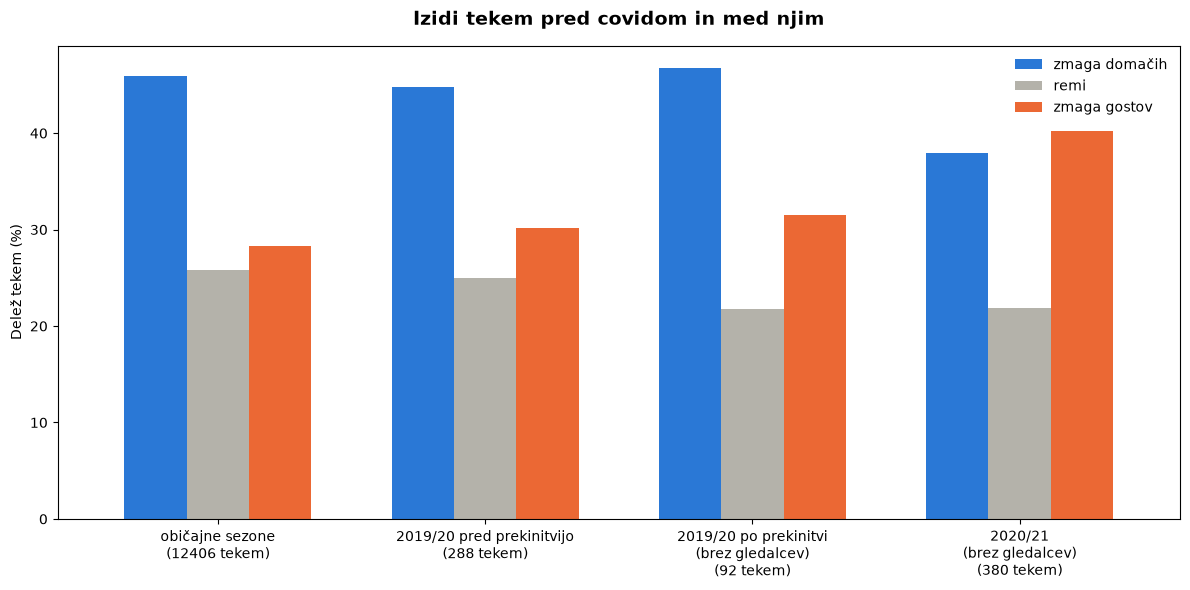

,zmaga domačih,remi,zmaga gostov
običajne sezone\n(12406 tekem),45.9,25.8,28.3
2019/20 pred prekinitvijo\n(288 tekem),44.8,25.0,30.2
2019/20 po prekinitvi\n(brez gledalcev)\n(92 tekem),46.7,21.7,31.5
2020/21\n(brez gledalcev)\n(380 tekem),37.9,21.8,40.3


In [4]:
def izidi_obdobja(lestvica):
    tekme = lestvica["tekme"].sum()
    return [lestvica["zmage"].sum() / tekme * 100,
            lestvica["remiji"].sum() / tekme * 100,
            lestvica["porazi"].sum() / tekme * 100]


stolpci = ["tekme", "zmage", "remiji", "porazi"]
konec_2019_20 = doma[doma["sezona"] == "2019-20"].set_index("klub")[stolpci]
do_prekinitve = lestvice[lestvice["vrsta"] == "doma_do_prekinitve"].set_index("klub")[stolpci]
po_prekinitvi = konec_2019_20 - do_prekinitve
obicajne = doma[~doma["sezona"].isin(["2019-20", "2020-21"])]
sezona_2020_21 = doma[doma["sezona"] == "2020-21"]

obdobja = {
    "običajne sezone": obicajne,
    "2019/20 pred prekinitvijo": do_prekinitve,
    "2019/20 po prekinitvi\n(brez gledalcev)": po_prekinitvi,
    "2020/21\n(brez gledalcev)": sezona_2020_21,
}

covid = pd.DataFrame(
    [izidi_obdobja(lestvica) for lestvica in obdobja.values()],
    index=[f"{ime}\n({lestvica['tekme'].sum()} tekem)" for ime, lestvica in obdobja.items()],
    columns=["zmaga domačih", "remi", "zmaga gostov"],
)

covid.plot(kind="bar", color=[MODRA, SIVA, ORANZNA], width=0.7, figsize=(12, 6))
plt.title("Izidi tekem pred covidom in med njim", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Delež tekem (%)")
plt.xticks(rotation=0)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

covid.round(1)

### Ključne ugotovitve
> V običajnih sezonah domači zmagajo na 45,9 % tekem, gostje na 28,3 %. V sezoni 2020/21 brez
> gledalcev so domači zmagali le na 37,9 % tekem, gostje pa celo pogosteje (40,3 %). Brez
> gledalcev je prednost domačega terena izginila, kar kaže, da jo v veliki meri prinašajo navijači.
> Na 92 tekmah po prekinitvi v sezoni 2019/20 tega še ni opaziti (domači 46,7 %), vendar je
> tekem premalo za zanesljiv sklep.

### 1.4 Kateri klubi imajo največjo prednost doma?

Za vsak klub, ki je v ligi igral vsaj 10 sezon, primerjam povprečne točke na tekmo doma in
v gosteh. Točke doma in v gosteh so izračunane kot 3 × zmage + remiji.

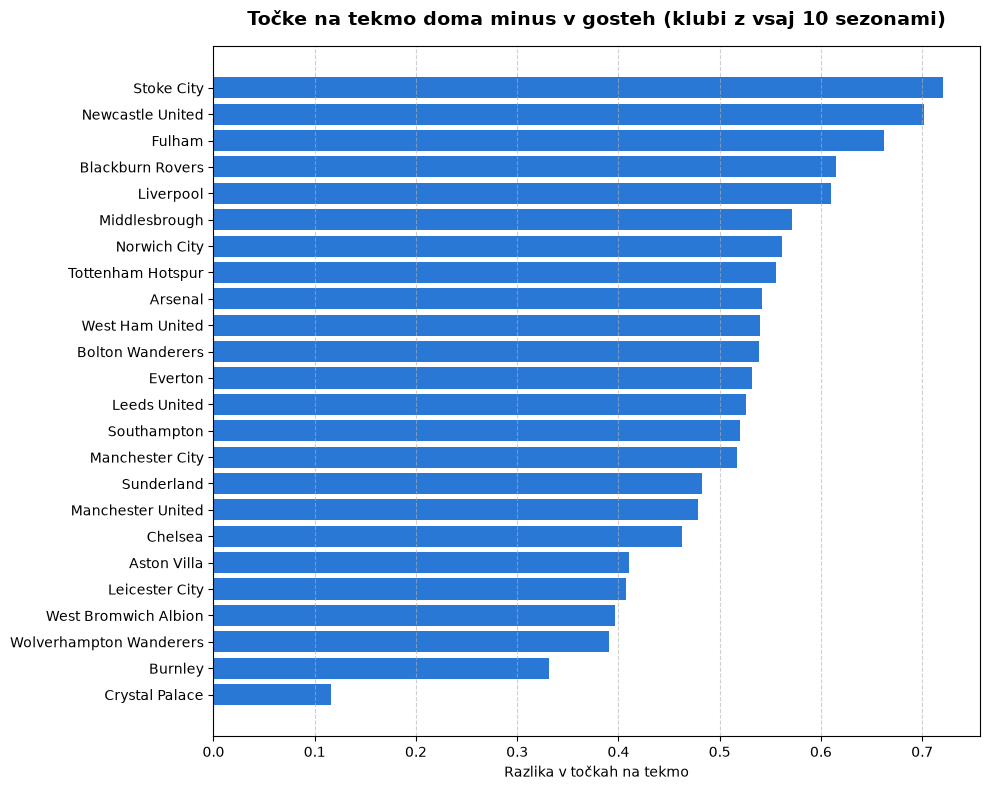

Vse tekme: doma 1.63, v gosteh 1.12 točke na tekmo


In [5]:
v_gosteh = lestvice[lestvice["vrsta"] == "v_gosteh"]
klubi_doma = doma.groupby("klub")[["tocke", "tekme"]].sum()
klubi_v_gosteh = v_gosteh.groupby("klub")[["tocke", "tekme"]].sum()
stevilo_sezon = doma.groupby("klub").size()

razlika = klubi_doma["tocke"] / klubi_doma["tekme"] - klubi_v_gosteh["tocke"] / klubi_v_gosteh["tekme"]
razlika = razlika[stevilo_sezon >= 10].sort_values()

plt.figure(figsize=(10, 8))
plt.barh(razlika.index, razlika, color=MODRA)
plt.title("Točke na tekmo doma minus v gosteh (klubi z vsaj 10 sezonami)",
          fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Razlika v točkah na tekmo")
plt.grid(True, axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Vse tekme: doma {doma['tocke'].sum() / doma['tekme'].sum():.2f}, "
      f"v gosteh {v_gosteh['tocke'].sum() / v_gosteh['tekme'].sum():.2f} točke na tekmo")

### Ključne ugotovitve
> Povprečno klubi osvojijo doma 1,63 točke na tekmo, v gosteh pa 1,12. Vseh 24 klubov z vsaj
> 10 sezonami osvoji doma več točk kot v gosteh, razlike pa so precejšnje: od 0,12 točke na
> tekmo pri Crystal Palace do 0,72 pri Stoke City.

---
## 2. Kdo je na vrhu in kdo na dnu lestvice?

### 2.1 Prvi trije

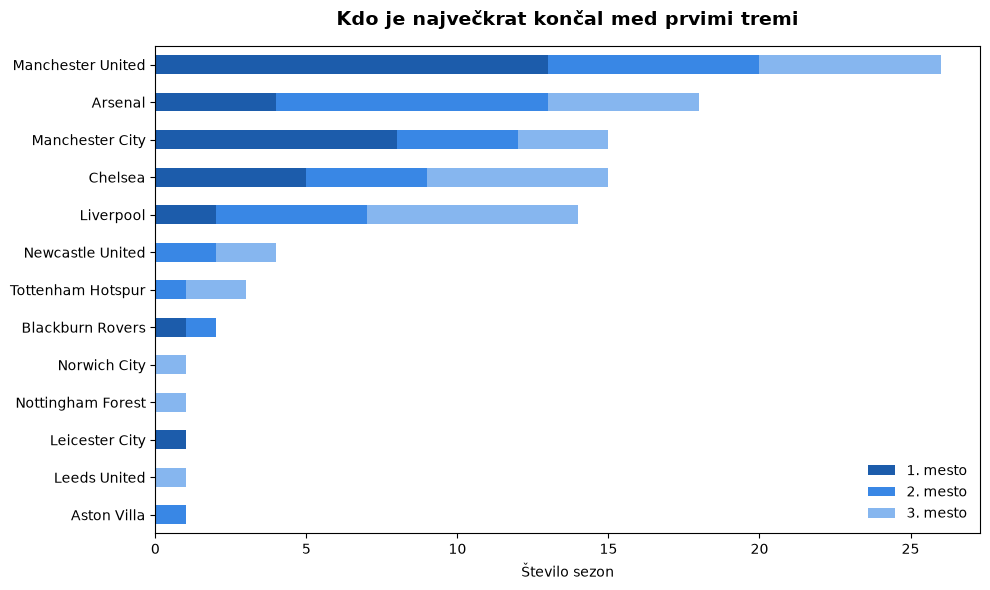

Prvaki:
klub
Manchester United    13
Manchester City       8
Chelsea               5
Arsenal               4
Liverpool             2
Blackburn Rovers      1
Leicester City        1
Name: count, dtype: int64


In [6]:
skupaj = lestvice[lestvice["vrsta"] == "skupaj"]
vrh = skupaj[skupaj["mesto"] <= 3].groupby(["klub", "mesto"]).size().unstack(fill_value=0)
vrh = vrh.loc[vrh.sum(axis=1).sort_values().index]

vrh.plot(kind="barh", stacked=True, color=["#1c5cab", "#3987e5", "#86b6ef"], figsize=(10, 6))
plt.title("Kdo je največkrat končal med prvimi tremi", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Število sezon")
plt.ylabel("")
plt.legend(["1. mesto", "2. mesto", "3. mesto"], frameon=False)
plt.tight_layout()
plt.show()

print("Prvaki:")
print(skupaj[skupaj["mesto"] == 1]["klub"].value_counts())

### Ključne ugotovitve
> Vrh lestvice je zelo zaprt: v 34 sezonah je bilo le 7 različnih prvakov, največ naslovov ima
> Manchester United (13). Med prvimi tremi je končalo 13 klubov, od tega jih 5 (Manchester United,
> Arsenal, Chelsea, Manchester City in Liverpool) zaseda 88 od 102 mest.

### 2.2 Zadnji trije

V prvih treh sezonah je bilo v ligi 22 klubov, zato so zadnja tri mesta takrat 20.–22. mesto,
kasneje pa 18.–20. mesto.

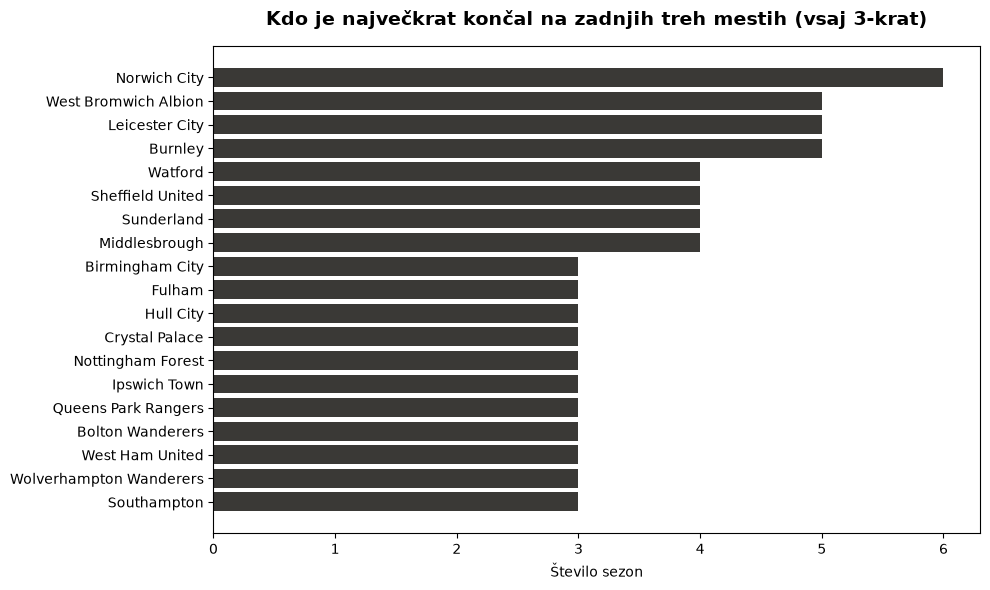

Različnih klubov na zadnjih treh mestih: 43


In [7]:
klubov_v_sezoni = skupaj.groupby("sezona")["klub"].transform("size")
zadnji = skupaj[skupaj["mesto"] > klubov_v_sezoni - 3]
dno = zadnji["klub"].value_counts()
dno = dno[dno >= 3].sort_values()

plt.figure(figsize=(10, 6))
plt.barh(dno.index, dno, color=TEMNO_SIVA)
plt.title("Kdo je največkrat končal na zadnjih treh mestih (vsaj 3-krat)",
          fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Število sezon")
plt.tight_layout()
plt.show()

print("Različnih klubov na zadnjih treh mestih:", zadnji["klub"].nunique())

### Ključne ugotovitve
> Dno je precej bolj raznoliko kot vrh: na zadnjih treh mestih je končalo kar 43 različnih
> klubov, večinoma takih, ki se selijo med Premier League in drugo ligo.

### 2.3 Razlika med vrhom in dnom

Za vsako sezono izračunam povprečne točke na tekmo prvih treh in zadnjih treh klubov
(na tekmo, ker so imele prve tri sezone 42 krogov, kasnejše pa 38).
Uporabljam točke s končne lestvice, torej z morebitnimi odbitki točk
(npr. Middlesbrough 1996/97, Everton in Nottingham Forest 2023/24).

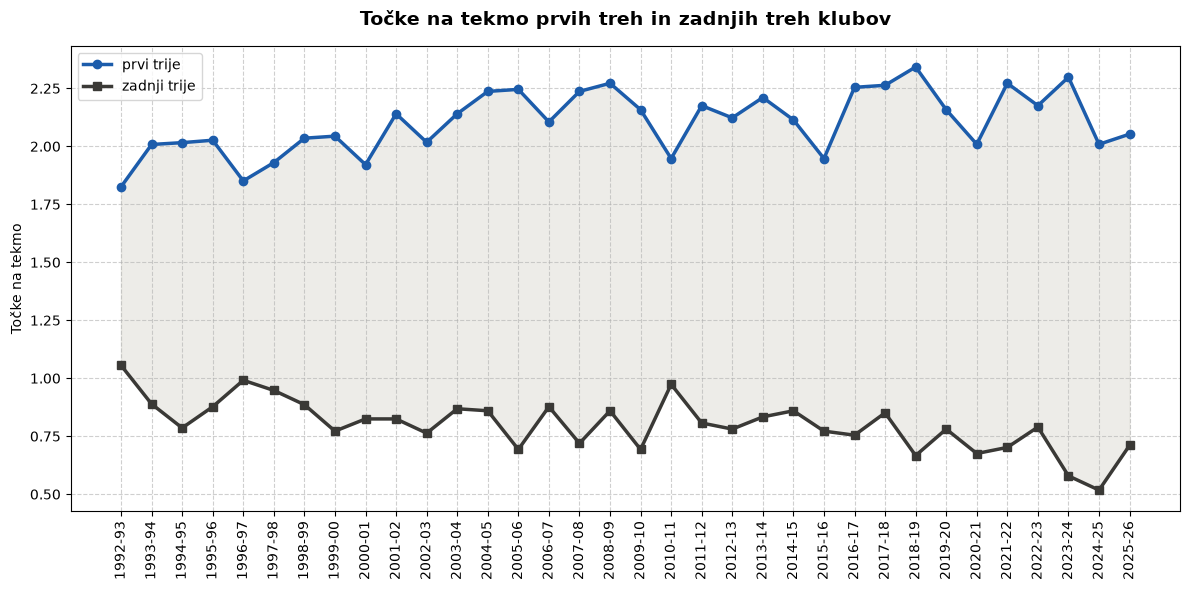

Razlika v prvih 10 sezonah:   1.09 točke na tekmo
Razlika v zadnjih 10 sezonah: 1.48 točke na tekmo


In [8]:
prvi = skupaj[skupaj["mesto"] <= 3]
prvi_trije = (prvi["tocke"] / prvi["tekme"]).groupby(prvi["sezona"]).mean()
zadnji_trije = (zadnji["tocke"] / zadnji["tekme"]).groupby(zadnji["sezona"]).mean()

plt.figure(figsize=(12, 6))
plt.plot(prvi_trije.index, prvi_trije, marker="o", color="#1c5cab", linewidth=2.5, label="prvi trije")
plt.plot(zadnji_trije.index, zadnji_trije, marker="s", color=TEMNO_SIVA, linewidth=2.5, label="zadnji trije")
plt.fill_between(prvi_trije.index, zadnji_trije, prvi_trije, color="#e1e0d9", alpha=0.6)

plt.title("Točke na tekmo prvih treh in zadnjih treh klubov", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Točke na tekmo")
plt.xticks(rotation=90)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

razlika_vrh_dno = prvi_trije - zadnji_trije
print(f"Razlika v prvih 10 sezonah:   {razlika_vrh_dno.head(10).mean():.2f} točke na tekmo")
print(f"Razlika v zadnjih 10 sezonah: {razlika_vrh_dno.tail(10).mean():.2f} točke na tekmo")

### Ključne ugotovitve
> Razlika med vrhom in dnom se veča: v prvih 10 sezonah so prvi trije osvojili v povprečju
> 1,09 točke na tekmo več kot zadnji trije, v zadnjih 10 sezonah pa že 1,48.

---
## Končne ugotovitve

- **Domači teren prinaša jasno prednost**: domači zmagajo na 45,7 % tekem, gostje na 28,7 %,
  doma pa dajo približno tretjino golov več.
- **Prednost prinašajo predvsem navijači**: v sezoni 2020/21, ko so tekme igrali brez
  gledalcev, je prednost domačih izginila, saj so gostje zmagali celo pogosteje kot domači.
- **Vrh lige je zaprt, dno odprto**: le 7 prvakov v 34 sezonah, na zadnjih treh mestih pa
  43 različnih klubov.
- **Liga je vse bolj neenakomerna**: razlika v točkah med prvimi tremi in zadnjimi tremi
  klubi se povečuje.